# Lab 04-08 · Energy in Fields and Maxwell's Equations (Preview)

Companion to chapter [04-08](../../chapters/04-08-maxwell-preview.md). Handout: [README.md](README.md). The ngspice netlist [stripline_delay.cir](stripline_delay.cir) simulates Example 04-08.3; run it with `python tools/run_spice.py 04-08` from the repository root.

The core of this lab is a **finite-difference time-domain (FDTD)** solver: Faraday's law and the Ampère–Maxwell law, discretized on a one-dimensional grid and stepped forward in time (Yee's method). Nothing else is put in; the waves come out. Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
c, mu0, eps0 = 299792458.0, 1.25663706127e-6, 8.8541878188e-12
N, dx = 4000, 0.5e-3
dt = 0.5 * dx / c                       # Courant number 0.5: stable

def fdtd(er, sig, steps, src, isrc, probes, snapshots=()):
    # E_y on integer cells, H_z on half cells. Faraday updates H, Ampère–Maxwell updates E.
    E, H = np.zeros(N), np.zeros(N - 1)
    loss = sig * dt / (2 * eps0 * er)
    ca, cb = (1 - loss) / (1 + loss), (dt / (eps0 * er * dx)) / (1 + loss)
    rec, snaps, energy = np.zeros((steps, len(probes))), {}, np.zeros(steps)
    for n in range(steps):
        H += dt / (mu0 * dx) * (E[1:] - E[:-1])
        E[1:-1] = ca[1:-1] * E[1:-1] + cb[1:-1] * (H[1:] - H[:-1])
        E[isrc] += src(n * dt)
        rec[n] = E[probes]
        energy[n] = np.sum(0.5 * eps0 * er * E**2) * dx + np.sum(0.5 * mu0 * H**2) * dx
        if n in snapshots:
            snaps[n] = E.copy()
    return rec, snaps, energy

## Part 1 — A pulse meets a dielectric

A Gaussian pulse starts in vacuum and hits a region with $\varepsilon_r$ = 4 at cell 2000.

**🔮 Predict:** the pulse's speed in the dielectric (as a fraction of $c$), and the sign and size of the reflected pulse.

reflected/incident = -0.3344   (theory (eta2-eta1)/(eta2+eta1) = -0.3333)
transmitted/incident = 0.6537   (theory 1 + Gamma = 0.6667)
speed in the dielectric = 0.4988 c   (theory 1/sqrt(4) = 0.5)


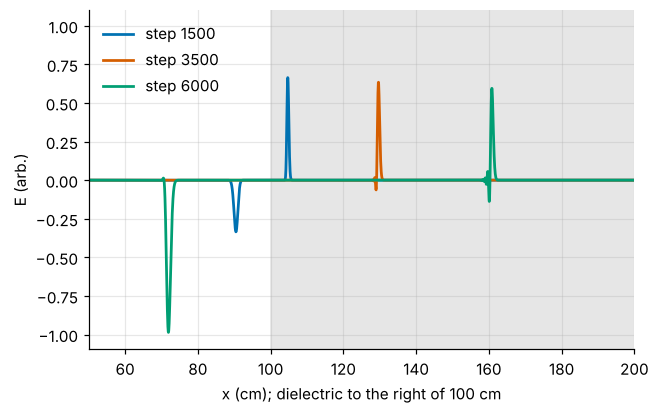

In [2]:
er, sig = np.ones(N), np.zeros(N)
er[2000:] = 4.0
t0, w = 100e-12, 25e-12
pulse = lambda t: math.exp(-((t - t0) / w) ** 2)
rec, snaps, energy = fdtd(er, sig, 9000, pulse, 1500, [1700, 2300, 2500], snapshots=(1500, 3500, 6000))
inc = rec[:, 0].max(); ip = rec[:, 0].argmax()
refl = rec[ip + 300:ip + 4000, 0].min()
trans = rec[:, 1].max()
t1, t2 = rec[:, 1].argmax(), rec[:, 2].argmax()
print(f"reflected/incident = {refl/inc:+.4f}   (theory (eta2-eta1)/(eta2+eta1) = {(0.5-1)/(0.5+1):+.4f})")
print(f"transmitted/incident = {trans/inc:.4f}   (theory 1 + Gamma = {1 + (0.5-1)/(0.5+1):.4f})")
print(f"speed in the dielectric = {200*dx/((t2-t1)*dt)/c:.4f} c   (theory 1/sqrt(4) = 0.5)")
x = np.arange(N) * dx * 100
for n, Es in snaps.items():
    plt.plot(x, Es, label=f"step {n}")
plt.axvspan(100, 200, color="0.9"); plt.xlim(50, 200)
plt.xlabel("x (cm); dielectric to the right of 100 cm"); plt.ylabel("E (arb.)"); plt.legend(); plt.show()

The grid reproduces the reflection coefficient and the halved speed to within about a percent, and the transmitted amplitude to about 2%; the residue is the grid's own numerical dispersion, which a finer grid reduces. The reflected pulse is inverted, as $\Gamma = (\eta_2 - \eta_1)/(\eta_2 + \eta_1) < 0$ predicts when the wave enters a lower-impedance medium.

## Part 2 — Energy bookkeeping

Track the total field energy $\sum(\tfrac12\varepsilon E^2 + \tfrac12\mu_0H^2)\,dx$ through the simulation.

**🔮 Predict:** does the energy change when the pulse splits at the interface?

energy after the source switches off: min 1.656614e-13, max 1.673445e-13 J/m^2 (spread 1.016 %)


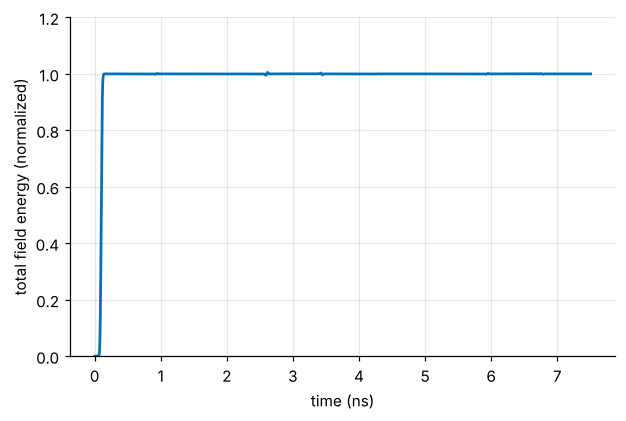

In [3]:
src_off = int(4 * t0 / dt)
e_after = energy[src_off:4000]
print(f"energy after the source switches off: min {e_after.min():.6e}, max {e_after.max():.6e} J/m^2 (spread {(e_after.max()/e_after.min()-1)*100:.3f} %)")
plt.plot(np.arange(len(energy)) * dt * 1e9, energy / energy[src_off]); plt.ylim(0, 1.2)
plt.xlabel("time (ns)"); plt.ylabel("total field energy (normalized)"); plt.show()

Once the source stops, the total energy stays constant through the reflection to about 1% (the grid's numerical error): the incident energy splits into reflected (11%) and transmitted (89%) parts, and the fields themselves carry it. (Energy eventually leaves when pulses reach the grid's edges, after the window shown.)

## Part 3 — A lossy dielectric

Give the dielectric a conductivity $\sigma = \omega\varepsilon\tan\delta$, equivalent to a loss tangent of 0.05 at 10 GHz, drive a 10 GHz sinusoid, and fit the decay of its amplitude.

**🔮 Predict:** the attenuation in Np/m from $\alpha = \pi f\sqrt{\varepsilon_r}\tan\delta/c$.

In [4]:
f, tand = 10e9, 0.05
sig2 = np.zeros(N); sig2[2000:] = 2 * math.pi * f * eps0 * 4.0 * tand
sine = lambda t: math.sin(2 * math.pi * f * t) * min(1.0, t / 0.5e-9)
probes = list(range(2100, 2600, 25))
rec3, _, _ = fdtd(er, sig2, 14000, sine, 1500, probes)
amp = np.abs(rec3[-3000:]).max(axis=0)
xs = np.array(probes) * dx
alpha_fit = -np.polyfit(xs, np.log(amp), 1)[0]
print(f"fitted attenuation: {alpha_fit:.2f} Np/m;  formula: {math.pi*f*2*tand/c:.2f} Np/m")

fitted attenuation: 10.53 Np/m;  formula: 10.48 Np/m


## Part 4 — Board materials

Dielectric loss in dB per meter against frequency, from datasheet values ([R-083](../../../../reference/research-log.md#r-083--board-dielectrics-propagation-5g-bands-and-rf-exposure)).

**🔮 Predict:** the FR-4-class laminate's loss at 5 GHz.

370HR at 5 GHz: 22.53 dB/m


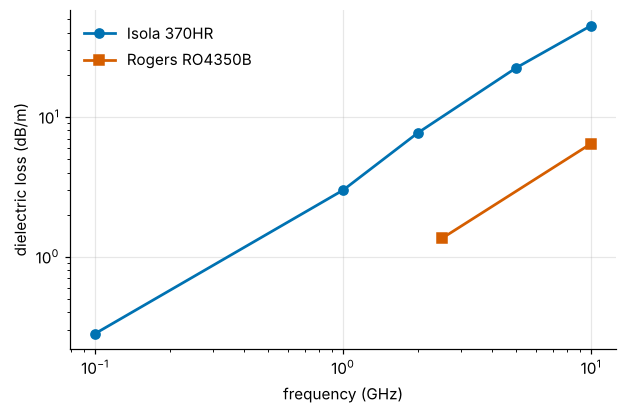

In [5]:
alpha_db = lambda f, dk, df: 20 / math.log(10) * math.pi * f * math.sqrt(dk) * df / c
fh = [0.1e9, 1e9, 2e9, 5e9, 10e9]; dkh = [4.24, 4.17, 4.04, 3.92, 3.92]; dfh = [0.0150, 0.0161, 0.0210, 0.0250, 0.0250]
plt.loglog(np.array(fh) / 1e9, [alpha_db(*z) for z in zip(fh, dkh, dfh)], "o-", label="Isola 370HR")
plt.loglog([2.5, 10], [alpha_db(2.5e9, 3.66, 0.0031), alpha_db(10e9, 3.66, 0.0037)], "s-", label="Rogers RO4350B")
print(f"370HR at 5 GHz: {alpha_db(5e9, 3.92, 0.025):.2f} dB/m")
plt.xlabel("frequency (GHz)"); plt.ylabel("dielectric loss (dB/m)"); plt.legend(); plt.show()

## Your turn

1. In Part 1, make the dielectric $\varepsilon_r$ = 2.25 (a typical cable dielectric). What fraction of power reflects? What happens if you add a quarter-wave layer of $\varepsilon_r$ = 1.5 in between, for a sinusoidal source?
2. In Part 3, halve the grid spacing. Does the fitted attenuation move closer to the formula? Why?